In [2]:
import pandas as pd 
# Load the CSV file into a DataFrame 
df = pd.read_csv('Iris.csv') 
# Display the first few rows of the DataFrame 
print(df.head()) 

   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa


In [3]:
# Display basic information about the DataFrame 
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB
None


In [4]:
# Display summary statistics for numerical columns 
print(df.describe()) 

               Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
count  150.000000     150.000000    150.000000     150.000000    150.000000
mean    75.500000       5.843333      3.054000       3.758667      1.198667
std     43.445368       0.828066      0.433594       1.764420      0.763161
min      1.000000       4.300000      2.000000       1.000000      0.100000
25%     38.250000       5.100000      2.800000       1.600000      0.300000
50%     75.500000       5.800000      3.000000       4.350000      1.300000
75%    112.750000       6.400000      3.300000       5.100000      1.800000
max    150.000000       7.900000      4.400000       6.900000      2.500000


In [5]:
# Check for missing values 
print(df.isnull().sum()) 
 
# Display rows with missing values 
print(df[df.isnull().any(axis=1)]) 

Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64
Empty DataFrame
Columns: [Id, SepalLengthCm, SepalWidthCm, PetalLengthCm, PetalWidthCm, Species]
Index: []


In [6]:
# Fill missing values with the mean of the column 
df.fillna(df.select_dtypes(include=['number']).mean(), inplace=True) 
 
# Alternatively, fill missing values with a specific value 
df.fillna(0, inplace=True)

In [7]:
# Display a specific column 
print(df['SepalLengthCm']) 
 
# Display a specific row 
print(df.iloc[0]) 
 
# Display a subset of the DataFrame 
print(df[['PetalWidthCm', 'Species']].head())

0      5.1
1      4.9
2      4.7
3      4.6
4      5.0
      ... 
145    6.7
146    6.3
147    6.5
148    6.2
149    5.9
Name: SepalLengthCm, Length: 150, dtype: float64
Id                         1
SepalLengthCm            5.1
SepalWidthCm             3.5
PetalLengthCm            1.4
PetalWidthCm             0.2
Species          Iris-setosa
Name: 0, dtype: object
   PetalWidthCm      Species
0           0.2  Iris-setosa
1           0.2  Iris-setosa
2           0.2  Iris-setosa
3           0.2  Iris-setosa
4           0.2  Iris-setosa


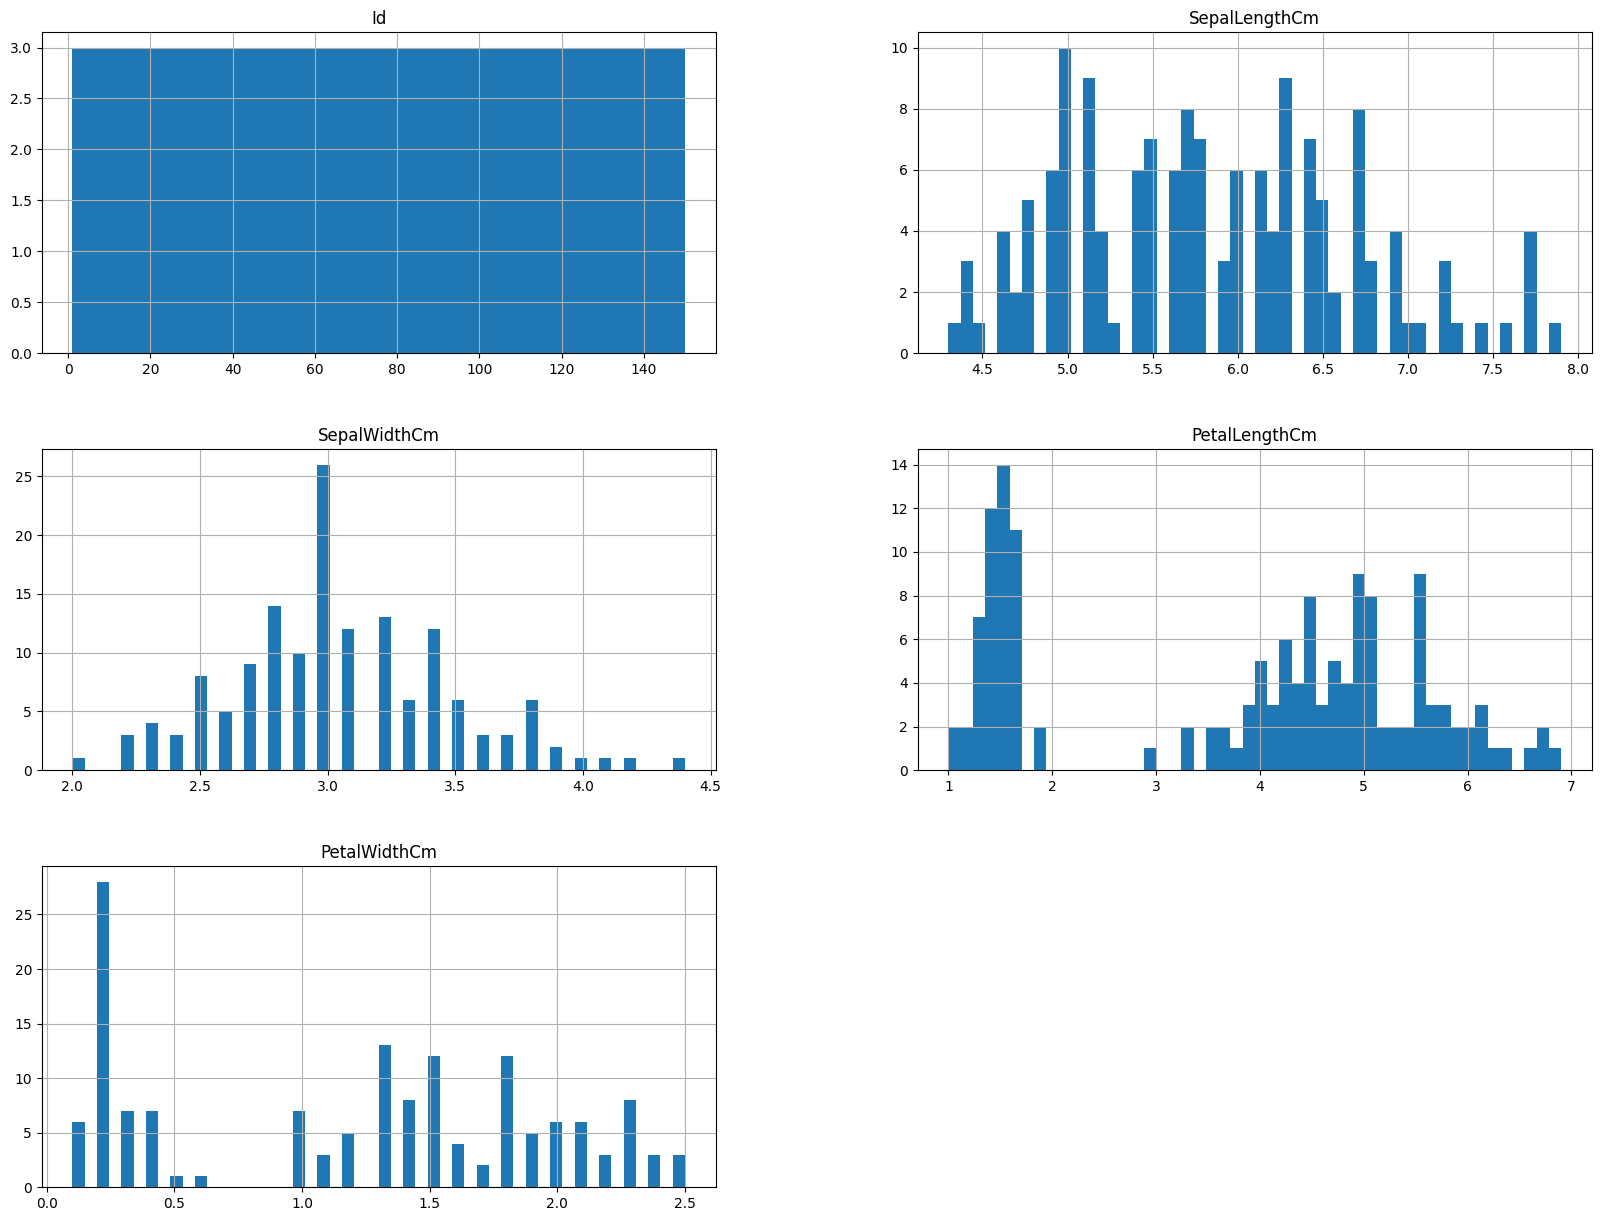

In [8]:
import matplotlib.pyplot as plt 
 
# Plot histograms for numerical columns 
df.hist(bins=50, figsize=(20, 15)) 
plt.show() 

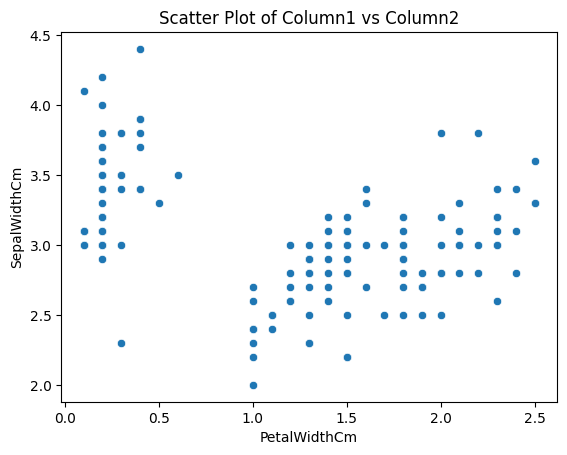

In [9]:
import seaborn as sns 
 
# Plot a scatter plot 
sns.scatterplot(x='PetalWidthCm', y='SepalWidthCm', data=df) 
plt.title('Scatter Plot of Column1 vs Column2') 
plt.show() 

In [11]:
# Identify outliers using Z-score 
from scipy import stats 
 
# Calculate Z-scores 
df['z_score'] = stats.zscore(df['SepalWidthCm']) 
 
# Display rows where Z-score is greater than 3 
print(df[df['z_score'].abs() > 3]) 

    Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species  \
15  16            5.7           4.4            1.5           0.4  Iris-setosa   

     z_score  
15  3.114684  


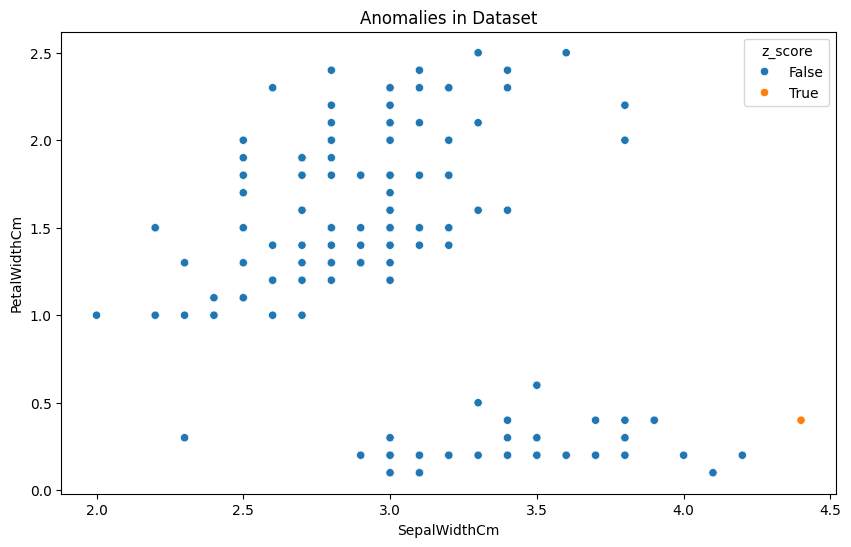

In [12]:
# Plotting anomalies 
plt.figure(figsize=(10, 6)) 
sns.scatterplot(x='SepalWidthCm', y='PetalWidthCm', hue=(df['z_score'].abs() > 3), data=df) 
plt.title('Anomalies in Dataset') 
plt.show() 

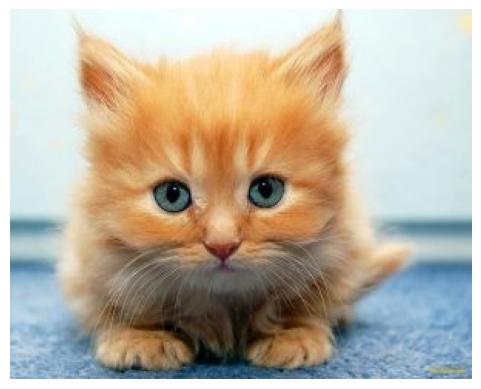

Image Format: JPEG
Image Size: (300, 240) (width, height)
Image Mode: RGB
Pixel at (10, 10): (231, 247, 247)


In [13]:
from PIL import Image 
import matplotlib.pyplot as plt 
 
# Open an image using PIL 
image_path = 'Picture1.jpg'  # Replace with your image path 
image = Image.open(image_path) 
 
# Display the image 
plt.imshow(image) 
plt.axis('off')  # Hides axes 
plt.show() 
 
# Explore image properties 
print(f"Image Format: {image.format}") 
print(f"Image Size: {image.size} (width, height)") 
print(f"Image Mode: {image.mode}") 
 
# Access pixel data 
pixels = image.load() 
 
# Print the pixel value at (x=10, y=10) 
print(f"Pixel at (10, 10): {pixels[10, 10]}") 
 
# Save the image in a different format (optional) 
image.save('output_image.png') 

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


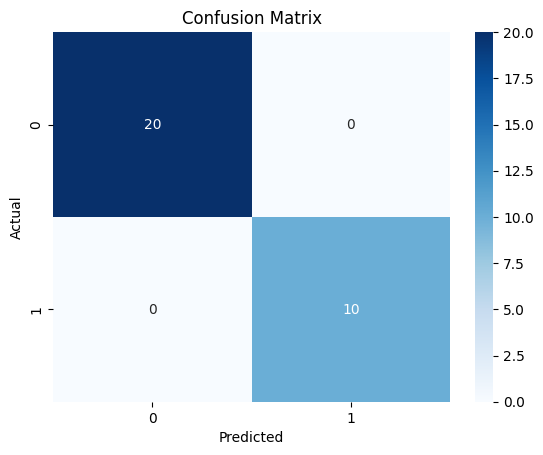

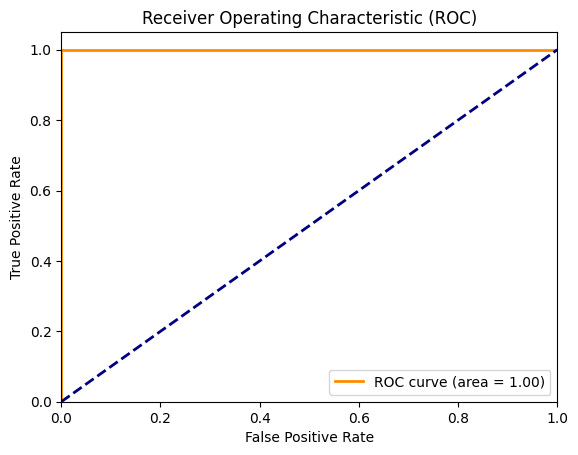

Sensitivity: 1.0
Specificity: 1.0


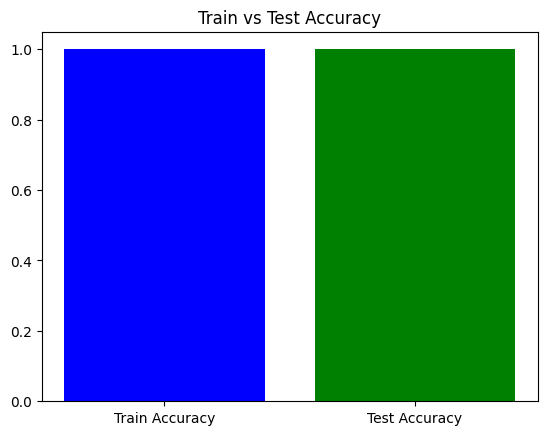

In [20]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.model_selection import train_test_split 
from sklearn.linear_model import LogisticRegression 
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score, roc_curve, roc_auc_score 
 
# Load the Iris dataset 
url = "Iris.csv" 
iris = pd.read_csv(url) 
 
# Prepare the dataset 
# For simplicity, we are converting the Species column to binary  classification (Setosa or Not Setosa) 
iris['Species'] = iris['Species'].apply(lambda x: 1 if x == 'Iris-setosa' 
else 0) 
 
# Define features (X) and target (y) 
X = iris[['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']] 
y = iris['Species'] 
 
# Split the data into training and testing datasets (80% training, 20% testing) 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, 
random_state=42) 
 
# Apply Logistic Regression (since Linear Regression is not ideal for classification tasks) 
model = LogisticRegression() 
model.fit(X_train, y_train) 
 
# Predict the testing dataset 
y_pred = model.predict(X_test) 
 
# Calculate accuracy, precision, recall, F1 Score 
accuracy = accuracy_score(y_test, y_pred) 
precision = precision_score(y_test, y_pred) 
recall = recall_score(y_test, y_pred) 
f1 = f1_score(y_test, y_pred) 
 
print(f"Accuracy: {accuracy}")

print(f"Precision: {precision}") 
print(f"Recall: {recall}") 
print(f"F1 Score: {f1}") 
 
# Confusion Matrix 
cm = confusion_matrix(y_test, y_pred) 
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues") 
plt.title("Confusion Matrix") 
plt.xlabel("Predicted") 
plt.ylabel("Actual") 
plt.show() 
 
# ROC Curve and AUC 
y_prob = model.predict_proba(X_test)[:, 1] 
fpr, tpr, thresholds = roc_curve(y_test, y_prob) 
roc_auc = roc_auc_score(y_test, y_prob) 
 
plt.figure() 
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc) 
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--') 
plt.xlim([0.0, 1.0]) 
plt.ylim([0.0, 1.05]) 
plt.xlabel('False Positive Rate') 
plt.ylabel('True Positive Rate') 
plt.title('Receiver Operating Characteristic (ROC)') 
plt.legend(loc="lower right") 
plt.show() 
 
# Sensitivity and Specificity 
sensitivity = recall 
specificity = cm[0, 0] / (cm[0, 0] + cm[0, 1]) 
print(f"Sensitivity: {sensitivity}") 
print(f"Specificity: {specificity}") 
 
# Plot accuracy of training vs testing 
train_accuracy = model.score(X_train, y_train) 
test_accuracy = model.score(X_test, y_test) 
 
plt.bar(['Train Accuracy', 'Test Accuracy'], [train_accuracy, 
test_accuracy], color=['blue', 'green']) 
plt.title('Train vs Test Accuracy') 
plt.show() 